<a href="https://colab.research.google.com/github/Cbl41K/StatsLab1/blob/cal_refractivity/cal_refractivity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Стохастической природа и эмпирическое исследование оценок

Величина cal_refractivity рассматривается как характеристика случайно выбранного препарата из базы данных DrugBank. Поскольку молекулы извлекаются случайным образом, их химическая структура, размер и поляризуемость электронного облака заранее не детерминированы. Значение рефракции варьируется от объекта к объекту под влиянием множества независимых структурных факторов, что обосновывает применение вероятностного подхода к её статистическому анализу.

In [3]:
import pandas as pd

url = "https://raw.githubusercontent.com/Cbl41K/StatsLab1/refs/heads/main/cleaned_data.csv"
df_cleaned = pd.read_csv(url)
df_cleaned.head(2)

,type,drugbank_id,name,state,cal_logp,cal_logs,cal_water_solubility,cal_molecular_weight,cal_polar_surface_area,cal_refractivity,cal_polarizability,cal_rotatable_bond_count,cal_h_bond_acceptor_count,cal_h_bond_donor_count,cal_pka_acidic,cal_pka_basic,cal_physiological_charge,cal_number_of_rings,cal_bioavailability,cal_rule_of_five
0,small molecule,DB00006,Bivalirudin,solid,-0.76,-4.7,0.0464,2180.2853,901.57,543.33,218.54,66.0,37.0,28.0,2.78,11.88,-4.0,6.0,0.0,0.0
1,small molecule,DB00007,Leuprolide,solid,1.04,-4.6,0.0338,1209.3983,429.04,327.24,125.24,32.0,16.0,16.0,9.49,11.92,1.0,6.0,0.0,0.0


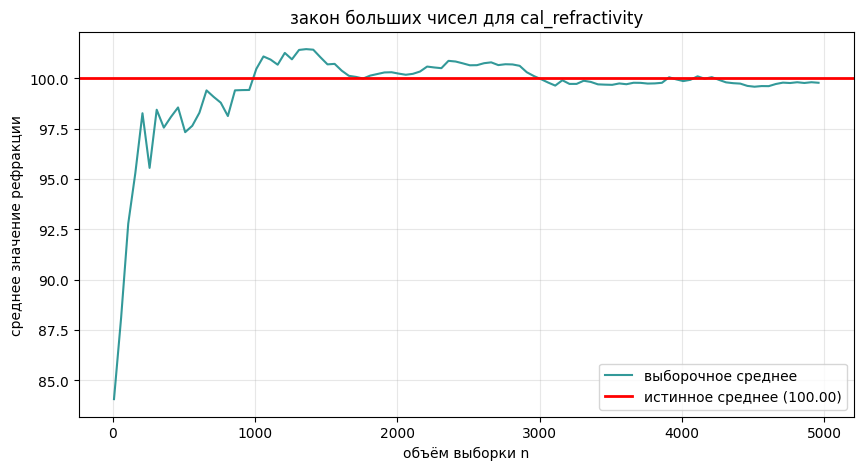

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

refractivity = df_cleaned['cal_refractivity'].dropna()
true_mean = refractivity.mean()
sample_sizes = np.arange(10, 5000, 50)
sample_means = []
for n in sample_sizes:
    sample = refractivity.sample(n=n, random_state=42)
    sample_means.append(sample.mean())

plt.figure(figsize=(10, 5))
plt.plot(sample_sizes, sample_means, label='выборочное среднее', color='teal', alpha=0.8)
plt.axhline(y=true_mean, color='red', linestyle='-', linewidth=2, label=f'истинное среднее ({true_mean:.2f})')

plt.title('закон больших чисел для cal_refractivity')
plt.xlabel('объём выборки n')
plt.ylabel('среднее значение рефракции')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

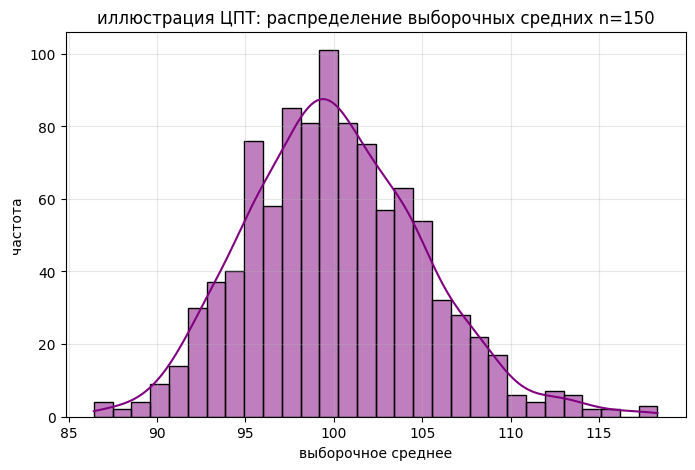

In [5]:
n_samples = 1000
sample_size = 150
clt_means = []

for _ in range(n_samples):
    sample = refractivity.sample(n=sample_size)
    clt_means.append(sample.mean())

plt.figure(figsize=(8, 5))
sns.histplot(clt_means, kde=True, color='purple', bins=30)
plt.title(f'иллюстрация ЦПТ: распределение выборочных средних n={sample_size}')
plt.xlabel('выборочное среднее')
plt.ylabel('частота')
plt.grid(True, alpha=0.3)
plt.show()

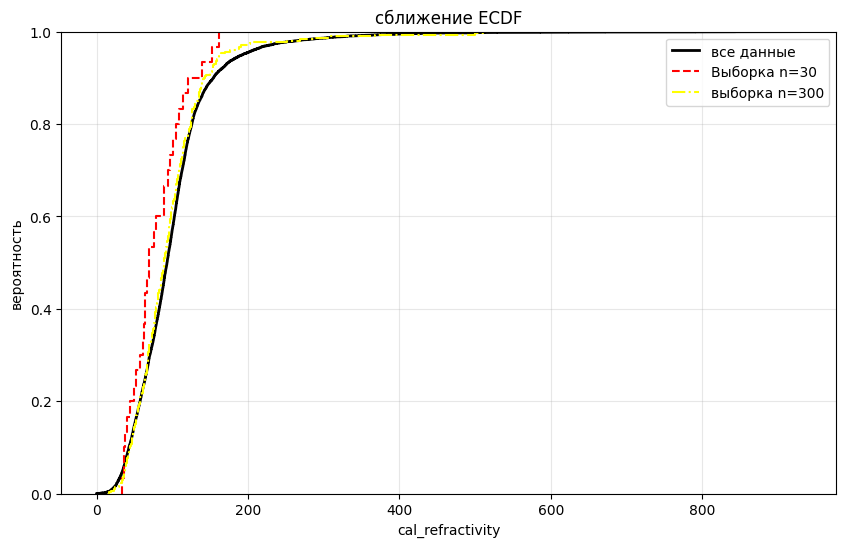

In [6]:
plt.figure(figsize=(10, 6))
sns.ecdfplot(data=refractivity, label='все данные', color='black', linewidth=2)

sample_small = refractivity.sample(n=30, random_state=42)
sns.ecdfplot(data=sample_small, label='Выборка n=30', color='red', linestyle='--')

sample_medium = refractivity.sample(n=300, random_state=42)
sns.ecdfplot(data=sample_medium, label='выборка n=300', color='yellow', linestyle='-.')

plt.title('сближение ECDF')
plt.xlabel('cal_refractivity')
plt.ylabel('вероятность')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Анализ пропусков
Отсутствие значения физического состояния state для почти четверти объектов может быть не случайным, а зависеть от характеристик самого вещества.
Чтобы это проверить, мы сравним cal_refractivity для двух независимых групп: где значение state пропущено, и где оно известно.

Для сравнения двух независимых выборок применяется t-критерий Стьюдента. Его базовое требование — нормальное распределение исследуемой величины. В предыдущем пункте с помощью теста Колмогорова-Смирнова мы доказали, что распределение cal_refractivity имеет сильную асимметрию и не является нормальным.
Применение параметрических тестов на таких данных приведёт к искажённым результатам. Поэтому как аналитический инструмент выбран **U-критерий Манна-Уитни** непараметрический тест, который сравнивает ранги значений и не требует закона нормального распределения

описательная статистика
Группа 'state пропущен' (n=2346): среднее = 117.29, медиана = 107.51
Группа 'state указан'  (n=7700): среднее = 94.74, медиана = 88.66



/tmp/ipykernel_1099/1197319032.py:21: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.boxplot(data=[group_filled, group_nan], ax=axes[1], palette=['skyblue', 'salmon'])
/tmp/ipykernel_1099/1197319032.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['state указан', 'state пропущен'])


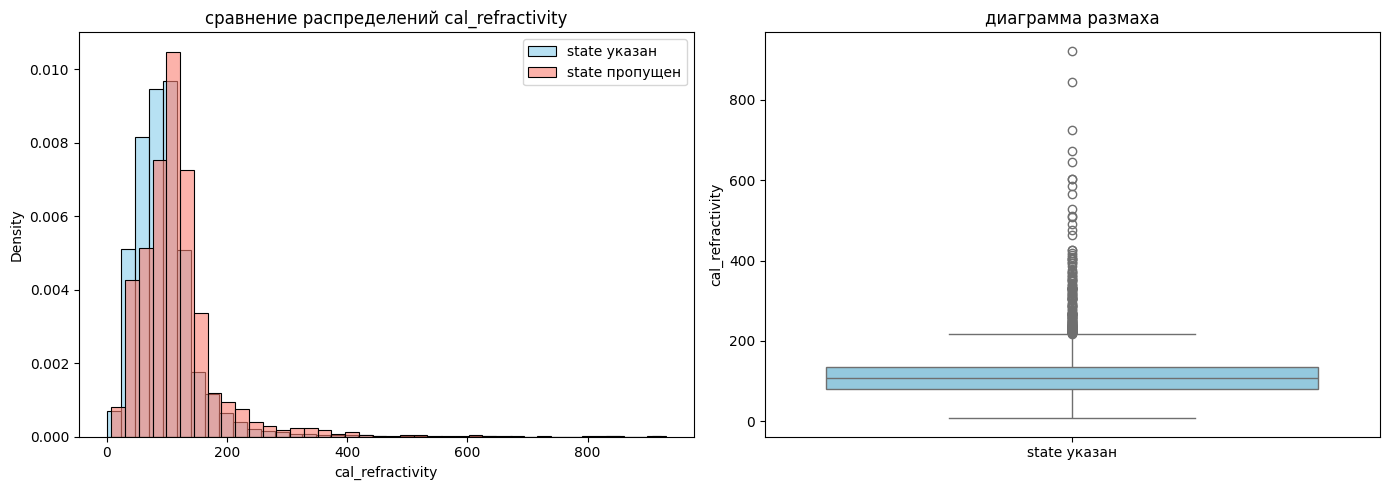


тест Манна-Уитни
Статистика U = 6756068.50, p-value = 1.81e-76
вывод по коду: отвергаем H0. распределения значимо различаются


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

group_nan = df_cleaned[df_cleaned['state'].isna()]['cal_refractivity'].dropna()
group_filled = df_cleaned[df_cleaned['state'].notna()]['cal_refractivity'].dropna()

print("описательная статистика")
print(f"Группа 'state пропущен' (n={len(group_nan)}): среднее = {group_nan.mean():.2f}, медиана = {group_nan.median():.2f}")
print(f"Группа 'state указан'  (n={len(group_filled)}): среднее = {group_filled.mean():.2f}, медиана = {group_filled.median():.2f}\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(group_filled, color='skyblue', alpha=0.6, stat='density', label='state указан', ax=axes[0], bins=40)
sns.histplot(group_nan, color='salmon', alpha=0.6, stat='density', label='state пропущен', ax=axes[0], bins=40)
axes[0].set_title('сравнение распределений cal_refractivity')
axes[0].legend()

sns.boxplot(data=[group_filled, group_nan], ax=axes[1], palette=['skyblue', 'salmon'])
axes[1].set_xticklabels(['state указан', 'state пропущен'])
axes[1].set_title('диаграмма размаха')
axes[1].set_ylabel('cal_refractivity')

plt.tight_layout()
plt.show()

stat, p_value = stats.mannwhitneyu(group_filled, group_nan, alternative='two-sided')
print("\nтест Манна-Уитни")
print(f"Статистика U = {stat:.2f}, p-value = {p_value:.2e}")

alpha = 0.05
if p_value < alpha:
    print("вывод по коду: отвергаем H0. распределения значимо различаются")
else:
    print("вывод по коду: нет оснований отвергнуть H0. распределения не имеют значимых различий")

**Вывод:**
Нулевая гипотеза отвергается: распределения cal_refractivity в двух группах имеют статистические различия $p = 1.81 \cdot 10^{-76}$

Соединения с пропущенным значением state обладают заметно большей молекулярной рефракцией. Это доказывает, что пропуски в данных **не случайны** и не являются простой ошибкой сбора. Отсутствие значения связано со свойствами самого вещества: для молекул с высокой рефракцией агрегатное состояние в бд фиксируется реже

## 2. Исследование зависимости характеристик

Молекулярная рефракция cal_refractivity и поляризуемость cal_polarizability описывают схожие физико-химические свойства вещества. Это даёт основание предполагать наличие прямой связи между ними.

Практическая задача в этом блоке, статистически подтвердить эту взаимосвязь на имеющихся данных. Если гипотеза о дублировании свойств подтвердится, это даст нам основания в будущем исключить один из признаков из предиктивных моделей, чтобы избежать проблемы мультиколлинеарности

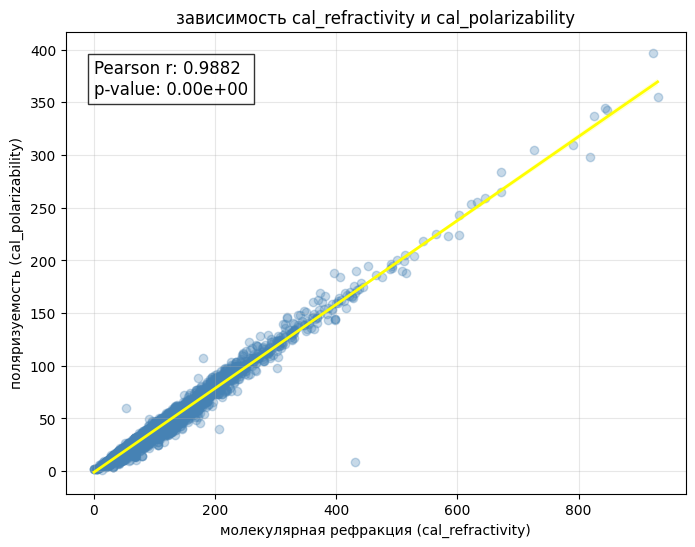

вывод по гипотезе 2:
p-value < 0.05. нулевая гипотеза отвергается. между признаками существует статистически значимая линейная связь.


In [ ]:
from scipy.stats import pearsonr

var_x = df_cleaned['cal_refractivity'].dropna()
var_y = df_cleaned['cal_polarizability'].dropna()
common_idx = var_x.index.intersection(var_y.index)
var_x = var_x.loc[common_idx]
var_y = var_y.loc[common_idx]
corr_coef, p_value = pearsonr(var_x, var_y)
plt.figure(figsize=(8, 6))
sns.regplot(
    x=var_x,
    y=var_y,
    scatter_kws={'alpha': 0.3, 'color': 'steelblue'},
    line_kws={'color': 'yellow', 'linewidth': 2}
)

plt.title(f'зависимость cal_refractivity и cal_polarizability')
plt.xlabel('молекулярная рефракция (cal_refractivity)')
plt.ylabel('поляризуемость (cal_polarizability)')
plt.text(
    x=var_x.min(), y=var_y.max() * 0.9,
    s=f"Pearson r: {corr_coef:.4f}\np-value: {p_value:.2e}",
    fontsize=12, bbox=dict(facecolor='white', alpha=0.8)
)

plt.grid(True, alpha=0.3)
plt.show()

print("вывод по гипотезе 2:")
if p_value < 0.05:
    print("p-value < 0.05. нулевая гипотеза отвергается. между признаками существует статистически значимая линейная связь")
else:
    print("p-value >= 0.05. нет оснований отвергнуть нулевую гипотезу. линейной связи не обнаружено")

## 3. EDA, нормализация и математическая модель

Исходное распределение молекулярной рефракции имеет сильную положительную асимметрию. Чтобы снизить влияние выбросов и привести данные к более симметричному виду, применяется логарифмическое преобразование.  
В качестве математической модели для данных мы проверим два распределения, которые хорошо описывают скошенные вправо положительные величиные **лог-нормальное** и **гамма-распределение**

эмпирические характеристики
среднее: 100.04
медиана: 93.16
стандартное отклонение: 60.24
асимметрия: 3.72



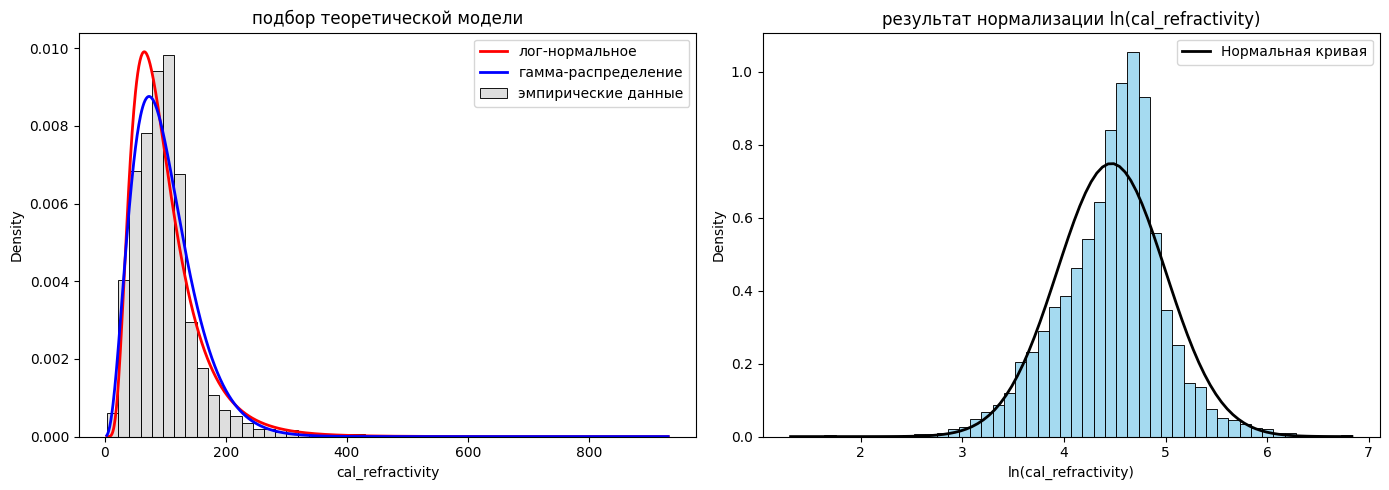

тест Колмогорова-Смирнова
KS Lognorm: KstestResult(statistic=np.float64(0.06416877528567833), pvalue=np.float64(2.161615850803564e-36), statistic_location=np.float64(82.5), statistic_sign=np.int8(-1))
KS Gamma: KstestResult(statistic=np.float64(0.0682836812772365), pvalue=np.float64(3.719041029744479e-41), statistic_location=np.float64(129.94), statistic_sign=np.int8(1))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

refractivity = df_cleaned['cal_refractivity'].dropna()
refractivity = refractivity[refractivity > 0]

print("эмпирические характеристики")
print(f"среднее: {refractivity.mean():.2f}")
print(f"медиана: {refractivity.median():.2f}")
print(f"стандартное отклонение: {refractivity.std():.2f}")
print(f"асимметрия: {refractivity.skew():.2f}\n")

log_refractivity = np.log(refractivity)
shape_ln, loc_ln, scale_ln = stats.lognorm.fit(refractivity, floc=0)
shape_g, loc_g, scale_g = stats.gamma.fit(refractivity, floc=0)

x = np.linspace(refractivity.min(), refractivity.max(), 1000)
pdf_lognorm = stats.lognorm.pdf(x, shape_ln, loc_ln, scale_ln)
pdf_gamma = stats.gamma.pdf(x, shape_g, loc_g, scale_g)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(refractivity, stat='density', bins=50, color='lightgray', ax=axes[0], label='эмпирические данные')
axes[0].plot(x, pdf_lognorm, 'red', lw=2, label='лог-нормальное')
axes[0].plot(x, pdf_gamma, 'blue', lw=2, label='гамма-распределение')
axes[0].set_title('подбор теоретической модели')
axes[0].set_xlabel('cal_refractivity')
axes[0].legend()

sns.histplot(log_refractivity, stat='density', bins=50, color='skyblue', ax=axes[1])
mu, std = stats.norm.fit(log_refractivity)
x_log = np.linspace(log_refractivity.min(), log_refractivity.max(), 100)
axes[1].plot(x_log, stats.norm.pdf(x_log, mu, std), 'k-', lw=2, label='Нормальная кривая')
axes[1].set_title('результат нормализации ln(cal_refractivity)')
axes[1].set_xlabel('ln(cal_refractivity)')
axes[1].legend()

plt.tight_layout()
plt.show()

print("тест Колмогорова-Смирнова")
print("KS Lognorm:", stats.kstest(refractivity, 'lognorm', args=(shape_ln, loc_ln, scale_ln)))
print("KS Gamma:", stats.kstest(refractivity, 'gamma', args=(shape_g, loc_g, scale_g)))

### критерий Колмогорова-Смирнова
Выбрать модель исключительно по визуальной форме гистограммы нельзя. Для этого мы применяем критерий согласия Колмогорова-Смирнова.  
Суть заключается в вычислении максимального расстояния между эмпирической функцией распределения наших данных и теоретической функцией. Применение этого критерия позволяет получить количественную оценку того, какая из двух гипотез точнее описывает реальные значения рефракции

## 4. Сравнение способов отбора выборки
Оценки математического ожидания и дисперсии при формировании выборки фиксированного объёма $n=500$ двумя методами: **без возвращения** и **с  возвращением**

In [ ]:
import pandas as pd

sample_size = 500
sample_no_repl = refractivity.sample(n=sample_size, replace=False, random_state=42)
sample_with_repl = refractivity.sample(n=sample_size, replace=True, random_state=42)
summary_df = pd.DataFrame({
 f'генеральная (N={len(refractivity)})': [refractivity.mean(), refractivity.var()],
 f'без возвращения (n={sample_size})': [sample_no_repl.mean(), sample_no_repl.var(ddof=1)],
 f'с возвращением (n={sample_size})': [sample_with_repl.mean(), sample_with_repl.var(ddof=1)]
}, index=['среднее', 'дисперсия'])

print("сравнение статистик в зависимости от метода отбора:")
display(summary_df.round(3))

сравнение статистик в зависимости от метода отбора:


,генеральная (N=10042),без возвращения (n=500),с возвращением (n=500)
среднее,100.044,99.189,98.804
дисперсия,3629.043,2961.948,3816.571


cal_polarizability

Была выявлена линейная зависимость между рефракцией и поляризуемостью, проведём аналогичный анализ распределения и выборочных оценок для величины cal_polarizability, чтобы визуально подтвердить дублирование их свойств

эмпирические характеристики cal_polarizability
среднее: 38.72
медиана: 35.61
стандартное отклонение: 24.28



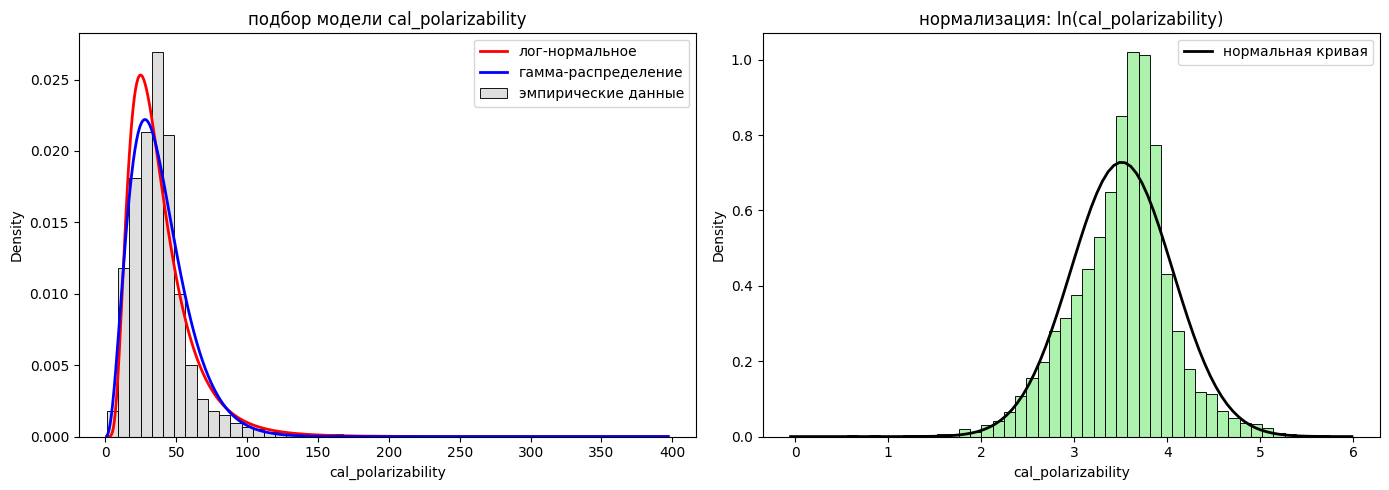

сравнение методов отбора cal_polarizability


,генеральная (N=10044),без возвращения (n=500),с возвращением (n=500)
среднее значение,38.717,36.806,39.485
дисперсия s^2,589.296,385.363,545.451


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pandas as pd

polarizability = df_cleaned['cal_polarizability'].dropna()
polarizability = polarizability[polarizability > 0]

print("эмпирические характеристики cal_polarizability")
print(f"среднее: {polarizability.mean():.2f}")
print(f"медиана: {polarizability.median():.2f}")
print(f"стандартное отклонение: {polarizability.std():.2f}\n")

log_polarizability = np.log(polarizability)
shape_ln, loc_ln, scale_ln = stats.lognorm.fit(polarizability, floc=0)
shape_g, loc_g, scale_g = stats.gamma.fit(polarizability, floc=0)

x = np.linspace(polarizability.min(), polarizability.max(), 1000)
pdf_lognorm = stats.lognorm.pdf(x, shape_ln, loc_ln, scale_ln)
pdf_gamma = stats.gamma.pdf(x, shape_g, loc_g, scale_g)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(polarizability, stat='density', bins=50, color='lightgray', ax=axes[0], label='эмпирические данные')
axes[0].plot(x, pdf_lognorm, 'red', lw=2, label='лог-нормальное')
axes[0].plot(x, pdf_gamma, 'blue', lw=2, label='гамма-распределение')
axes[0].set_title('подбор модели cal_polarizability')
axes[0].legend()

sns.histplot(log_polarizability, stat='density', bins=50, color='lightgreen', ax=axes[1])
mu, std = stats.norm.fit(log_polarizability)
x_log = np.linspace(log_polarizability.min(), log_polarizability.max(), 100)
axes[1].plot(x_log, stats.norm.pdf(x_log, mu, std), 'k-', lw=2, label='нормальная кривая')
axes[1].set_title('нормализация: ln(cal_polarizability)')
axes[1].legend()

plt.tight_layout()
plt.show()

sample_size = 500
sample_no_repl_pol = polarizability.sample(n=sample_size, replace=False, random_state=42)
sample_with_repl_pol = polarizability.sample(n=sample_size, replace=True, random_state=42)

summary_df_pol = pd.DataFrame({
    f'генеральная (N={len(polarizability)})': [polarizability.mean(), polarizability.var(ddof=0)],
    f'без возвращения (n={sample_size})': [sample_no_repl_pol.mean(), sample_no_repl_pol.var(ddof=1)],
    f'с возвращением (n={sample_size})': [sample_with_repl_pol.mean(), sample_with_repl_pol.var(ddof=1)]
}, index=['среднее значение', 'дисперсия s^2'])

print("сравнение методов отбора cal_polarizability")
display(summary_df_pol.round(3))

## влияние на фармакологические свойства
мы проверяем, различается ли молекулярная рефракция cal_refractivity у веществ с разными фармакологическими свойствами. В качестве группирующих признаков выступают бинарные флаги биодоступности cal_bioavailability и соответствия правилу пяти Липински cal_rule_of_five

Распределение рефракции отличается от нормального, для проверки различий между группами. мы используем непараметрический **U-критерий Манна-Уитни**. Анализ проводится отдельно для каждого из двух показателей

/tmp/ipykernel_1099/3295214560.py:14: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.boxplot(data=[group_bio_0, group_bio_1], ax=axes[0, 1], palette=['salmon', 'skyblue'])
/tmp/ipykernel_1099/3295214560.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['bio = 0', 'bio = 1'])
/tmp/ipykernel_1099/3295214560.py:25: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.boxplot(data=[group_ro5_0, group_ro5_1], ax=axes[1, 1], palette=['salmon', 'lightgreen'])
/tmp/ipykernel_1099/3295214560.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 1].set_xticklabels(['ro5 = 0', 'ro5 = 1'])


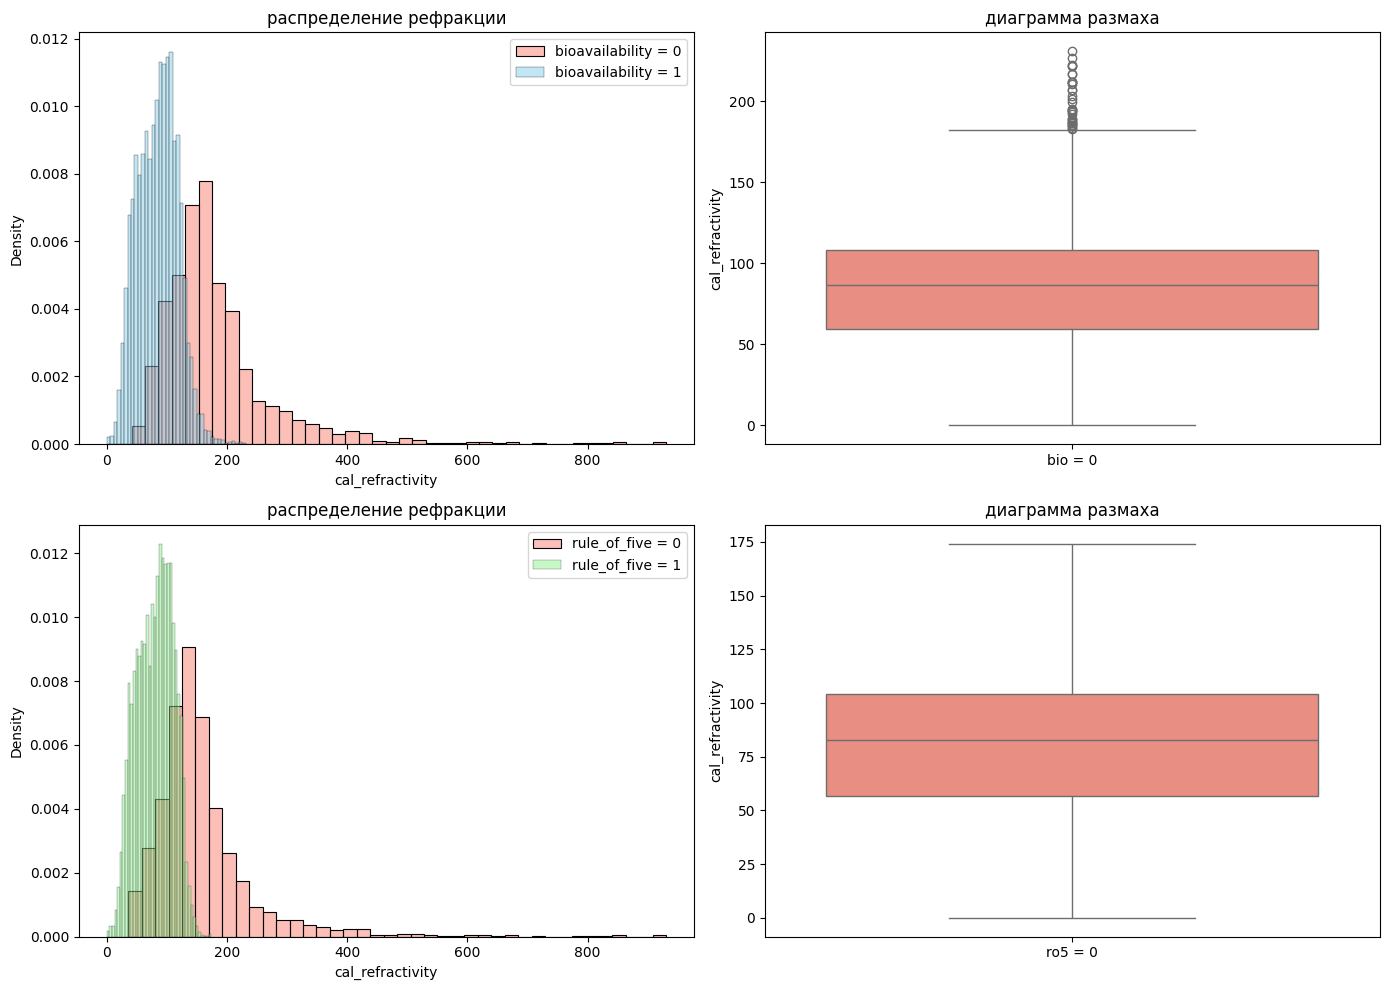

тест Манна-Уитни биодоступность
медиана 0: 161.24 | Медиана 1: 86.42
p-value = 0.00e+00

тест Манна-Уитни правило Пяти
медиана 0: 141.49 | Медиана 1: 82.81
p-value = 0.00e+00


In [13]:
group_bio_0 = df_cleaned[df_cleaned['cal_bioavailability'] == 0]['cal_refractivity'].dropna()
group_bio_1 = df_cleaned[df_cleaned['cal_bioavailability'] == 1]['cal_refractivity'].dropna()

group_ro5_0 = df_cleaned[df_cleaned['cal_rule_of_five'] == 0]['cal_refractivity'].dropna()
group_ro5_1 = df_cleaned[df_cleaned['cal_rule_of_five'] == 1]['cal_refractivity'].dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(group_bio_0, color='salmon', alpha=0.5, stat='density', label='bioavailability = 0', ax=axes[0, 0], bins=40)
sns.histplot(group_bio_1, color='skyblue', alpha=0.5, stat='density', label='bioavailability = 1', ax=axes[0, 0], bins=40)
axes[0, 0].set_title('распределение рефракции')
axes[0, 0].legend()

sns.boxplot(data=[group_bio_0, group_bio_1], ax=axes[0, 1], palette=['salmon', 'skyblue'])
axes[0, 1].set_xticklabels(['bio = 0', 'bio = 1'])
axes[0, 1].set_title('диаграмма размаха')
axes[0, 1].set_ylabel('cal_refractivity')

# Графики для Правила Пяти
sns.histplot(group_ro5_0, color='salmon', alpha=0.5, stat='density', label='rule_of_five = 0', ax=axes[1, 0], bins=40)
sns.histplot(group_ro5_1, color='lightgreen', alpha=0.5, stat='density', label='rule_of_five = 1', ax=axes[1, 0], bins=40)
axes[1, 0].set_title('распределение рефракции')
axes[1, 0].legend()

sns.boxplot(data=[group_ro5_0, group_ro5_1], ax=axes[1, 1], palette=['salmon', 'lightgreen'])
axes[1, 1].set_xticklabels(['ro5 = 0', 'ro5 = 1'])
axes[1, 1].set_title('диаграмма размаха')
axes[1, 1].set_ylabel('cal_refractivity')

plt.tight_layout()
plt.show()

print("тест Манна-Уитни биодоступность")
stat_bio, p_bio = stats.mannwhitneyu(group_bio_0, group_bio_1, alternative='two-sided')
print(f"медиана 0: {group_bio_0.median():.2f} | Медиана 1: {group_bio_1.median():.2f}")
print(f"p-value = {p_bio:.2e}")

print("\nтест Манна-Уитни правило Пяти")
stat_ro5, p_ro5 = stats.mannwhitneyu(group_ro5_0, group_ro5_1, alternative='two-sided')
print(f"медиана 0: {group_ro5_0.median():.2f} | Медиана 1: {group_ro5_1.median():.2f}")
print(f"p-value = {p_ro5:.2e}")

## 5. Итоги исследования случайной величины

**Выборки**

Мы рассматривали рефракцию случайно выбранного вещества из базы. Затем проверили, насколько хорошо случайные выборки передают свойства полного набора. При увеличении объёма выборки среднее в целом становилось ближе к среднему всех данных, а эмпирическая функция распределения точнее воспроизводила распределение полного набора. Отдельно рассмотрели распределение выборочных средних и проиллюстрировали его приближение к нормальному. Так на наших данных были показаны ЗБЧ, ЦПТ и теорема Гливенко—Кантелли

**Связь с поляризуемостью**


 Мы получили корреляцию около 0,99 между **cal_refractivity** и **cal_polarizability**:чем выше рефракция вещества, тем выше и его поляризуемость. Это даёт повод проверить, нужны ли в модели оба признака, но только на основе одной корреляции удалять вторую, не логично, поэтому нужно сравнить качество предсказаний с двумя признаками и с одним

**Распределение**


Основная часть значений сосредоточена в левой части диапазона, а редкие большие значения дают длинный правый хвост. Поэтому в качестве возможных моделей мы рассмотрели гамма и логнормальное распределения. Выбрать одно из них только по форме графика нельзя нужна проверка согласия с данными. Логарифмическое преобразование помогло сжать хвост, но само по себе не делает распределение нормальным поэтому в столбце есть нули, для преобразования всех наблюдений мы использовали $\ln(1+x)$, а не $\ln(x)$

**Способы отбора**


Сравнение выборок с возвращением и без показало, что при достаточно большом объёме генеральной совокупности $N > 10000$ и умеренном объёме выборки $n=500$ оба метода дают схожие оценки параметров

**Различия статистически подтверждены $p \approx 0$**

У биодоступных веществ и тех, что подходят под правило пяти, рефракция почти в два раза ниже. чем меньше рефракция, тем компактнее молекула. Небольшим молекулам гораздо проще проникать сквозь мембраны клеток, поэтому они лучше усваиваются организмом и чаще становятся успешными лекарствами